# Data import
Za početak importamo datasetove. Korišteni datasetovi su preuzeti iz istraživanja pronađenog na internetu. U dokumentaciji se nalazi detaljna usporedba dobivenih rezultata s onima iz tog istraživanja, kao i poveznice na originalni istraživački rad.
Dokumentacija također sadrži detaljnu analizu svih dobivenih rezultata, kao i opis svakog koraka pri treniranju modela.

In [49]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler


In [50]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: /Users/enesek/Documents/projekt-R/testiranje/regresijski_modeli/combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 

In [51]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

In [52]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [53]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])

# One-hot encoding the categorical features (keep all columns)
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']
combined_data = pd.get_dummies(combined_data, columns=categorical_features)

# Numeric features: No scaling needed for Random Forest
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [54]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [55]:
# Definiranje značajki (X) i ciljne varijable (y)
X = combined_data.drop(columns=['G3'])  # G3 je ciljna varijabla
y = combined_data['G3']                # Ciljna varijabla - konačna ocjena

# Podjela podataka na trening i testne skupove
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [56]:
# Inicijalizacija Random Forest modela
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Treniranje modela na trening skupu
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

Nakon treniranja modela koristimo onih 20% kako bi testirali model i predvidjeli podatke. Mean Squared Error i R-suqared nam govore o vjerodostojnosti modela.

In [57]:
# Predviđanje na testnom skupu
y_pred = rf_model.predict(X_test)

# Evaluacija modela
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse}")
print(f"R-squared (R²): {r2}")


Mean Squared Error (MSE): 2.8300299363057326
R-squared (R²): 0.8092506797884617


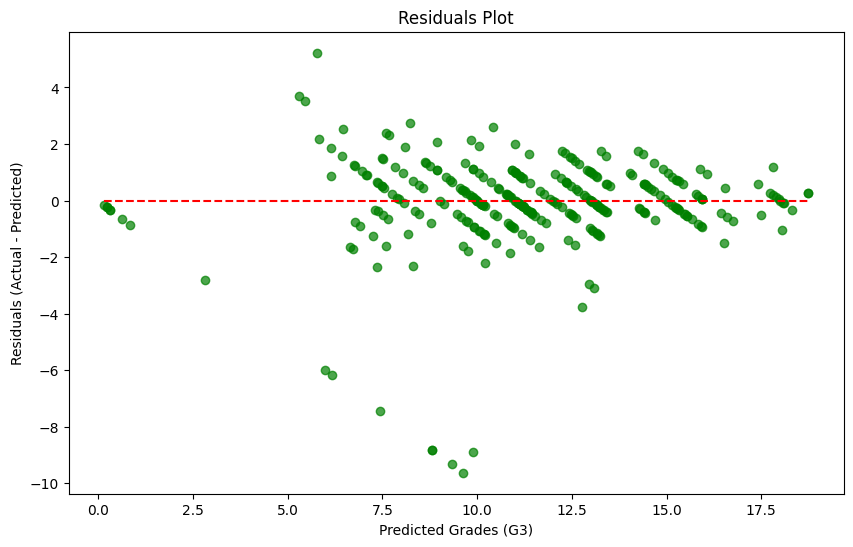

In [58]:
import matplotlib.pyplot as plt

# Residuals
residuals = y_test - y_pred

# Plot Residuals
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='g')
plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), color='r', linestyle='--')
plt.xlabel("Predicted Grades (G3)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals Plot")
plt.show()


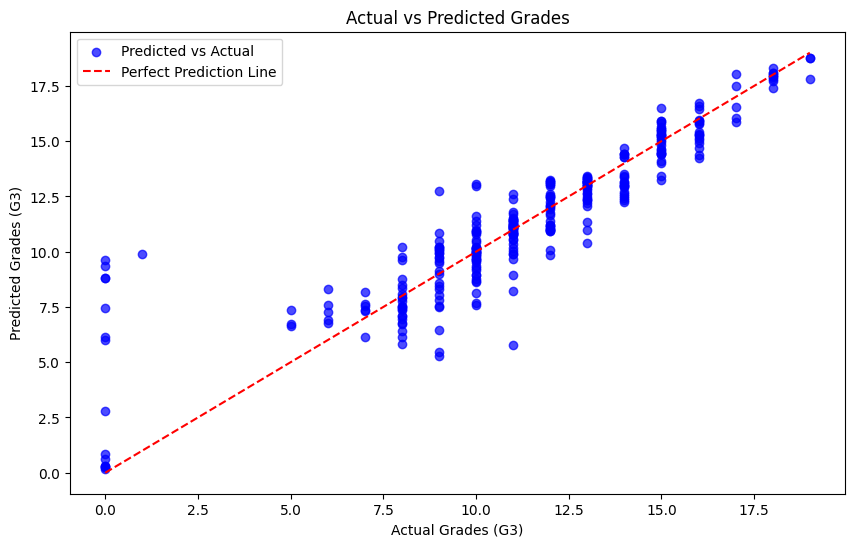

In [59]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='r', linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Grades (G3)")
plt.ylabel("Predicted Grades (G3)")
plt.title("Actual vs Predicted Grades")
plt.legend()
plt.show()


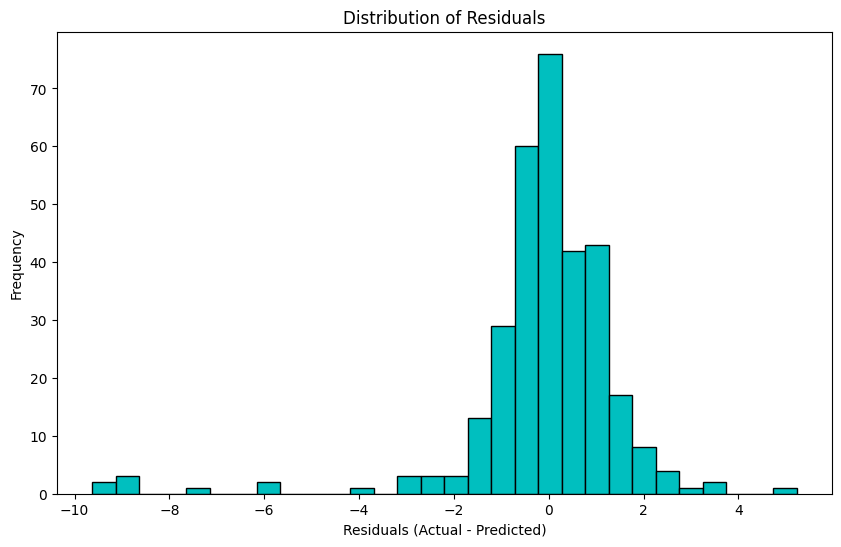

In [60]:
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, color='c', edgecolor='black')
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()


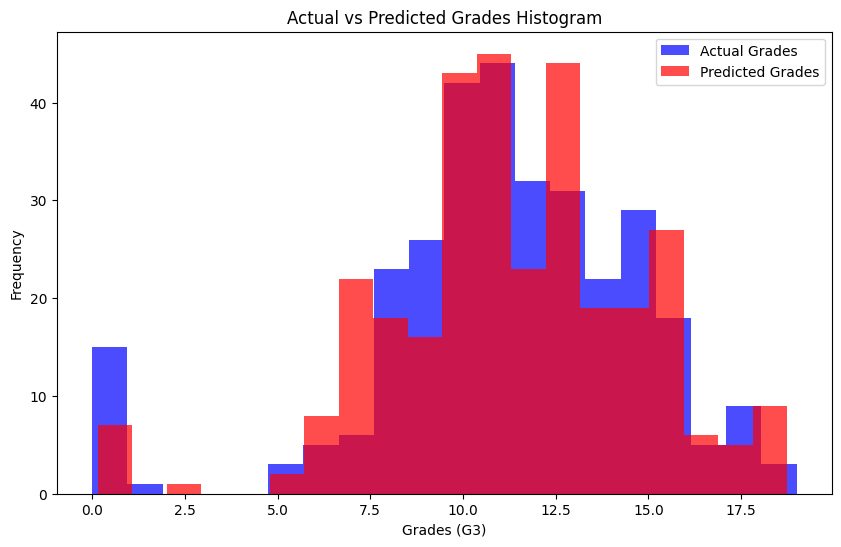

In [61]:
# Actual vs Predicted Grades Histogram
plt.figure(figsize=(10, 6))
plt.hist(y_test, bins=20, alpha=0.7, label='Actual Grades', color='b')
plt.hist(y_pred, bins=20, alpha=0.7, label='Predicted Grades', color='r')
plt.xlabel("Grades (G3)")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Grades Histogram")
plt.legend()
plt.show()

# Optimizacija modela

In [62]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],  # Number of trees in the forest
    'max_depth': [10, 20, None],      # Maximum depth of the tree
    'min_samples_split': [2, 5, 10],  # Minimum number of samples required to split a node
    'min_samples_leaf': [1, 2, 4],    # Minimum number of samples required to be at a leaf node
    'max_features': ['sqrt', 'log2', None],  # Number of features to consider at each split
}

# Initialize the RandomForestRegressor
rf_model = RandomForestRegressor(random_state=42)

# Initialize GridSearchCV
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=5, n_jobs=-1, scoring='r2')

# Fit GridSearchCV
grid_search.fit(X_train, y_train)

# Get the best parameters and the best score
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best R² Score: {grid_search.best_score_}")

# Use the best model to make predictions
best_rf_model = grid_search.best_estimator_
y_pred_best = best_rf_model.predict(X_test)

# Evaluate the optimized model
best_mse = mean_squared_error(y_test, y_pred_best)
best_r2 = r2_score(y_test, y_pred_best)

print(f"Optimized Mean Squared Error: {best_mse}")
print(f"Optimized R-squared: {best_r2}")


Best Parameters: {'max_depth': 20, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Best R² Score: 0.8605379331132958
Optimized Mean Squared Error: 2.6658014933589924
Optimized R-squared: 0.8203199845507932


In [63]:
from sklearn.feature_selection import SelectKBest, f_regression

# Select top 10 features based on the univariate statistical test
selector = SelectKBest(score_func=f_regression, k=10)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Initialize and train the Random Forest model with selected features
rf_model_selected = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_selected.fit(X_train_selected, y_train)

# Make predictions
y_pred_selected = rf_model_selected.predict(X_test_selected)

# Evaluate the model
selected_mse = mean_squared_error(y_test, y_pred_selected)
selected_r2 = r2_score(y_test, y_pred_selected)

print(f"Feature Selection - Mean Squared Error: {selected_mse}")
print(f"Feature Selection - R-squared: {selected_r2}")


Feature Selection - Mean Squared Error: 3.3694341928038387
Feature Selection - R-squared: 0.7728938222420938
